#  01 - EDA, Sampling, Feature Engineering & Selection

## Dataset
Hotel Booking Demand dataset  
**Source:** [Kaggle](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)

The dataset contains 119,390 booking records and 32 columns. The cancellation
target is `is_canceled` (`1` = canceled, `0` = not canceled).

## Objective
Explore the dataset, examine sampling strategies, engineer and select features,
and prepare the data for cancellation analysis.

In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('hotel_bookings.csv')
print(df.shape)
df.head()

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [83]:
aggregation = (
    df.groupby(["hotel", "market_segment"])["adr"]
      .agg(
          mean_adr="mean",
          median_adr="median",
          std_adr="std",
          count="size"
      )
      .reset_index()
)

aggregation

,hotel,market_segment,mean_adr,median_adr,std_adr,count
0,City Hotel,Aviation,100.142110,95.00,21.796583,237
1,City Hotel,Complementary,2.600424,0.00,14.168495,542
2,City Hotel,Corporate,83.119980,79.00,25.082872,2986
3,City Hotel,Direct,119.479682,111.25,47.651490,6093
4,City Hotel,Groups,84.921885,75.00,31.144895,13975
5,City Hotel,Offline TA/TO,93.017660,90.00,49.540186,16747
6,City Hotel,Online TA,118.919533,114.00,38.113785,38748
7,City Hotel,Undefined,15.000000,15.00,4.242641,2
8,Resort Hotel,Complementary,3.657413,0.00,13.680883,201
9,Resort Hotel,Corporate,51.563183,42.00,30.665794,2309


In [84]:
aggregation["small_group"] = aggregation["count"] < 30

aggregation

,hotel,market_segment,mean_adr,median_adr,std_adr,count,small_group
0,City Hotel,Aviation,100.142110,95.00,21.796583,237,False
1,City Hotel,Complementary,2.600424,0.00,14.168495,542,False
2,City Hotel,Corporate,83.119980,79.00,25.082872,2986,False
3,City Hotel,Direct,119.479682,111.25,47.651490,6093,False
4,City Hotel,Groups,84.921885,75.00,31.144895,13975,False
5,City Hotel,Offline TA/TO,93.017660,90.00,49.540186,16747,False
6,City Hotel,Online TA,118.919533,114.00,38.113785,38748,False
7,City Hotel,Undefined,15.000000,15.00,4.242641,2,True
8,Resort Hotel,Complementary,3.657413,0.00,13.680883,201,False
9,Resort Hotel,Corporate,51.563183,42.00,30.665794,2309,False


In [85]:
small_groups = aggregation[aggregation["small_group"]]

small_groups

,hotel,market_segment,mean_adr,median_adr,std_adr,count,small_group
7,City Hotel,Undefined,15.0,15.0,4.242641,2,True


In [86]:
pd.set_option("display.max_columns", None)

pivot_table = pd.pivot_table(
    df,
    index="hotel",
    columns="market_segment",
    values="adr",
    aggfunc=["mean", "median", "std", "count"]
).round(2)

pivot_table

mean                                                       \
market_segment Aviation Complementary Corporate  Direct Groups Offline TA/TO   
hotel                                                                          
City Hotel       100.14          2.60     83.12  119.48  84.92         93.02   
Resort Hotel        NaN          3.66     51.56  111.67  66.45         74.66   

                                     median                                  \
market_segment Online TA Undefined Aviation Complementary Corporate  Direct   
hotel                                                                         
City Hotel        118.92      15.0     95.0           0.0      79.0  111.25   
Resort Hotel      113.43       NaN      NaN           0.0      42.0   93.00   

                                                             std  \
market_segment Groups Offline TA/TO Online TA Undefined Aviation   
hotel                                                              
City Hotel       75.0          90.0     114.0      15.0     21.8   
Resort Hotel     66.0          64.9      95.0       NaN      NaN   

                                                                              \
market_segment Complementary Corporate Direct Groups Offline TA/TO Online TA   
hotel                                                                          
City Hotel             14.17     25.08  47.65  31.14         49.54     38.11   
Resort Hotel           13.68     30.67  68.19  32.07         41.53     66.39   

                            count                                           \
market_segment Undefined Aviation Complementary Corporate  Direct   Groups   
hotel                                                                        
City Hotel          4.24    237.0         542.0    2986.0  6093.0  13975.0   
Resort Hotel         NaN      NaN         201.0    2309.0  6513.0   5836.0   

                                                  
market_segment Offline TA/TO Online TA Undefined  
hotel                                             
City Hotel           16747.0   38748.0       2.0  
Resort Hotel          7472.0   17729.0       NaN

In [87]:
#part 1.2
# the total number of nights
df["total_nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

df[[
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "total_nights"
]].head()

,stays_in_weekend_nights,stays_in_week_nights,total_nights
0,0,0,0
1,0,0,0
2,0,1,1
3,0,1,1
4,0,2,2


In [88]:
weighted_df = df[
    (df["total_nights"] > 0) &
    (df["adr"].notna())
].copy()

In [89]:
weighted_df["adr_times_nights"] = (
    weighted_df["adr"] *
    weighted_df["total_nights"]
)

In [90]:
# new columns: total_nights and adr_times_nights
weighted_df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_nights,adr_times_nights
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,1,75.00
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,1,75.00
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03,2,196.00
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03,2,196.00
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,NaN,NaN,0,Transient,107.00,0,0,Check-Out,2015-07-03,2,214.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,0.0,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06,7,672.98
119386,City Hotel,0,102,2017,August,35,31,2,5,3,0.0,0,BB,FRA,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07,7,1578.01
119387,City Hotel,0,34,2017,August,35,31,2,5,2,0.0,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07,7,1103.97
119388,City Hotel,0,109,2017,August,35,31,2,5,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07,7,730.80


In [91]:
weighted_aggregation = (
    weighted_df
    .groupby(["hotel", "market_segment"])
    .agg(
        unweighted_mean=("adr", "mean"),
        weighted_sum=("adr_times_nights", "sum"),
        total_weight=("total_nights", "sum"),
        booking_count=("adr", "size")
    )
    .reset_index()
)

weighted_aggregation

,hotel,market_segment,unweighted_mean,weighted_sum,total_weight,booking_count
0,City Hotel,Aviation,102.743203,87446.36,855,231
1,City Hotel,Complementary,2.715665,2937.99,792,519
2,City Hotel,Corporate,83.595911,484068.62,5684,2969
3,City Hotel,Direct,120.647945,2122531.51,17536,6034
4,City Hotel,Groups,84.970526,3121991.05,35583,13967
5,City Hotel,Offline TA/TO,93.480962,4475201.98,48652,16664
6,City Hotel,Online TA,119.335304,14985244.45,127151,38613
7,City Hotel,Undefined,15.000000,48.00,3,2
8,Resort Hotel,Complementary,3.657413,2144.53,432,201
9,Resort Hotel,Corporate,52.379846,290226.64,5398,2273


In [92]:
# Weighted mean = sum(ADR × total_nights) / sum(total_nights)
weighted_aggregation["weighted_mean"] = (
    weighted_aggregation["weighted_sum"] /
    weighted_aggregation["total_weight"]
)

In [93]:
weighted_aggregation["absolute_divergence"] = (
    weighted_aggregation["weighted_mean"] -
    weighted_aggregation["unweighted_mean"]
).abs()

In [94]:
weighted_aggregation["percentage_divergence"] = (
    weighted_aggregation["absolute_divergence"] /
    weighted_aggregation["unweighted_mean"].abs() *
    100
)

In [95]:
result = weighted_aggregation[[
    "hotel",
    "market_segment",
    "booking_count",
    "unweighted_mean",
    "weighted_mean",
    "absolute_divergence",
    "percentage_divergence"
]].copy()

result = result.round(2)

result

,hotel,market_segment,booking_count,unweighted_mean,weighted_mean,absolute_divergence,percentage_divergence
0,City Hotel,Aviation,231,102.74,102.28,0.47,0.45
1,City Hotel,Complementary,519,2.72,3.71,0.99,36.60
2,City Hotel,Corporate,2969,83.60,85.16,1.57,1.88
3,City Hotel,Direct,6034,120.65,121.04,0.39,0.32
4,City Hotel,Groups,13967,84.97,87.74,2.77,3.26
5,City Hotel,Offline TA/TO,16664,93.48,91.98,1.50,1.60
6,City Hotel,Online TA,38613,119.34,117.85,1.48,1.24
7,City Hotel,Undefined,2,15.00,16.00,1.00,6.67
8,Resort Hotel,Complementary,201,3.66,4.96,1.31,35.73
9,Resort Hotel,Corporate,2273,52.38,53.77,1.39,2.65


In [96]:
largest_divergence = result.loc[
    result["absolute_divergence"].idxmax()
]

largest_divergence

hotel                    Resort Hotel
market_segment                 Direct
booking_count                    6436
unweighted_mean                113.01
weighted_mean                  129.85
absolute_divergence             16.85
percentage_divergence           14.91
Name: 10, dtype: object

In [97]:
print(
    f"The largest divergence was found for "
    f"{largest_divergence['hotel']} in the "
    f"{largest_divergence['market_segment']} segment."
)

print(
    f"Unweighted mean: "
    f"{largest_divergence['unweighted_mean']:.2f}"
)

print(
    f"Weighted mean: "
    f"{largest_divergence['weighted_mean']:.2f}"
)

print(
    f"Absolute divergence: "
    f"{largest_divergence['absolute_divergence']:.2f}"
)

print(
    f"Percentage divergence: "
    f"{largest_divergence['percentage_divergence']:.2f}%"
)

The largest divergence was found for Resort Hotel in the Direct segment.
Unweighted mean: 113.01
Weighted mean: 129.85
Absolute divergence: 16.85
Percentage divergence: 14.91%


ADR was weighted by the total number of booked nights because longer reservations contribute more room-nights than shorter reservations. 

The largest divergence was observed for Resort Hotel bookings in the Direct segment. 

The unweighted mean ADR was 113.01, while the weighted mean was 129.85, producing an absolute divergence of 16.85 and a percentage divergence of 14.91%.

Since the weighted mean is higher, longer direct bookings at the Resort Hotel tend to have higher daily rates than shorter bookings.

One possible explanation is that longer direct stays may occur during expensive peak-season periods or may include higher-priced room types and packages; this is a hypothesis that would require further analysis.

In [98]:
#1.3
cv_df = df[
    (df["adr"].notna()) &
    (df["adr"] >= 0)
].copy()

In [99]:
month_mapping = {
    "January": 1,
    "February": 2,
    "March": 3,
    "April": 4,
    "May": 5,
    "June": 6,
    "July": 7,
    "August": 8,
    "September": 9,
    "October": 10,
    "November": 11,
    "December": 12
}

cv_df["arrival_month_number"] = (
    cv_df["arrival_date_month"].map(month_mapping)
)

In [100]:
#creating complete arrival data like 2017-08-15
cv_df["arrival_date"] = pd.to_datetime({
    "year": cv_df["arrival_date_year"],
    "month": cv_df["arrival_month_number"],
    "day": cv_df["arrival_date_day_of_month"]
})

In [101]:
cv_df[[
    "arrival_date_year",
    "arrival_date_month",
    "arrival_date_day_of_month",
    "arrival_date"
]].head()

,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date
0,2015,July,1,2015-07-01
1,2015,July,1,2015-07-01
2,2015,July,1,2015-07-01
3,2015,July,1,2015-07-01
4,2015,July,1,2015-07-01


In [102]:
# Level 1: individual bookings
raw_mean = cv_df["adr"].mean()
raw_std = cv_df["adr"].std()
raw_cv = raw_std / raw_mean

In [103]:
#groups all bookings with the same arrival date and calculates one mean ADR for each day.
# Level 2: daily average ADR
daily_adr = (
    cv_df.groupby("arrival_date")["adr"]
         .mean()
)

In [104]:
daily_mean = daily_adr.mean()
daily_std = daily_adr.std()
daily_cv = daily_std / daily_mean

In [105]:
#only year and month
cv_df["arrival_year_month"] = (
    cv_df["arrival_date"].dt.to_period("M")
)

In [106]:
# Level 3: monthly average ADR
monthly_adr = (
    cv_df.groupby("arrival_year_month")["adr"]
         .mean()
)

In [107]:
#monthly CV
monthly_mean = monthly_adr.mean()
monthly_std = monthly_adr.std()
monthly_cv = monthly_std / monthly_mean

In [108]:
cv_results = pd.DataFrame({
    "granularity": [
        "Individual bookings",
        "Daily averages",
        "Monthly averages"
    ],
    "number_of_observations": [
        len(cv_df),
        len(daily_adr),
        len(monthly_adr)
    ],
    "mean_adr": [
        raw_mean,
        daily_mean,
        monthly_mean
    ],
    "std_adr": [
        raw_std,
        daily_std,
        monthly_std
    ],
    "cv": [
        raw_cv,
        daily_cv,
        monthly_cv
    ]
})

cv_results["cv_percent"] = cv_results["cv"] * 100

cv_results.round(3)

,granularity,number_of_observations,mean_adr,std_adr,cv,cv_percent
0,Individual bookings,119389,101.832,50.535,0.496,49.626
1,Daily averages,793,98.210,29.038,0.296,29.567
2,Monthly averages,26,98.475,26.389,0.268,26.798


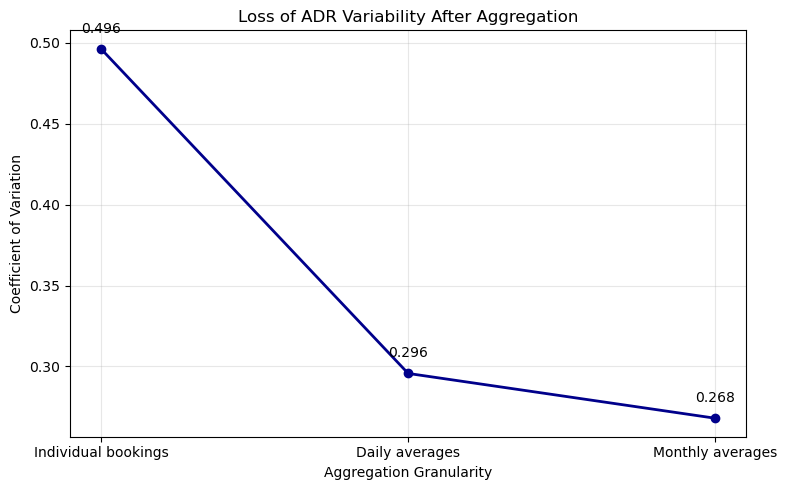

In [109]:
plt.figure(figsize=(8, 5))

plt.plot(
    cv_results["granularity"],
    cv_results["cv"],
    marker="o",
    linewidth=2,
    color="darkblue"
)

for x, y in zip(
    cv_results["granularity"],
    cv_results["cv"]
):
    plt.text(
        x,
        y + 0.01,
        f"{y:.3f}",
        ha="center"
    )

plt.title("Loss of ADR Variability After Aggregation")
plt.xlabel("Aggregation Granularity")
plt.ylabel("Coefficient of Variation")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The coefficient of variation decreased from 0.496 at the individual-booking level to 0.296 at the daily level and 0.268 at the monthly level. The largest reduction occurred between individual booking and daily averages, where CV decreased by 0.2. Therefore, aggregation started to hide meaningful ADR variation at this stage because individual price differences were replaced by broader average values.

In [110]:
cv_df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_nights,arrival_month_number,arrival_date,arrival_year_month
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01,0,7,2015-07-01,2015-07
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01,0,7,2015-07-01,2015-07
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,1,7,2015-07-01,2015-07
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,1,7,2015-07-01,2015-07
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03,2,7,2015-07-01,2015-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,0.0,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06,7,8,2017-08-30,2017-08
119386,City Hotel,0,102,2017,August,35,31,2,5,3,0.0,0,BB,FRA,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07,7,8,2017-08-31,2017-08
119387,City Hotel,0,34,2017,August,35,31,2,5,2,0.0,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07,7,8,2017-08-31,2017-08
119388,City Hotel,0,109,2017,August,35,31,2,5,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07,7,8,2017-08-31,2017-08


In [111]:
individual_level = cv_df[[
    "arrival_date",
    "adr"
]].copy()

individual_level["granularity"] = "Individual booking"
individual_level["period"] = (
    individual_level["arrival_date"].astype(str)
)
individual_level["adr_value"] = individual_level["adr"]
individual_level["source_count"] = 1

individual_level = individual_level[[
    "granularity",
    "period",
    "adr_value",
    "source_count"
]]

daily_level = (
    cv_df.groupby("arrival_date")["adr"]
         .agg(
             adr_value="mean",
             source_count="size"
         )
         .reset_index()
)

daily_level["granularity"] = "Daily average"
daily_level["period"] = (
    daily_level["arrival_date"].astype(str)
)

daily_level = daily_level[[
    "granularity",
    "period",
    "adr_value",
    "source_count"
]]

monthly_level = (
    cv_df.groupby("arrival_year_month")["adr"]
         .agg(
             adr_value="mean",
             source_count="size"
         )
         .reset_index()
)

monthly_level["granularity"] = "Monthly average"
monthly_level["period"] = (
    monthly_level["arrival_year_month"].astype(str)
)

monthly_level = monthly_level[[
    "granularity",
    "period",
    "adr_value",
    "source_count"
]]


three_levels = pd.concat(
    [
        individual_level,
        daily_level,
        monthly_level
    ],
    ignore_index=True
)

three_levels["adr_value"] = (
    three_levels["adr_value"].round(2)
)

three_levels_preview = (
    three_levels
    .groupby("granularity", sort=False)
    .head(5)
    .reset_index(drop=True)
)

three_levels_preview

,granularity,period,adr_value,source_count
0,Individual booking,2015-07-01,0.00,1
1,Individual booking,2015-07-01,0.00,1
2,Individual booking,2015-07-01,75.00,1
3,Individual booking,2015-07-01,75.00,1
4,Individual booking,2015-07-01,98.00,1
5,Daily average,2015-07-01,92.83,122
6,Daily average,2015-07-02,82.21,93
7,Daily average,2015-07-03,97.18,56
8,Daily average,2015-07-04,85.58,88
9,Daily average,2015-07-05,100.00,53


In [112]:
#part2
import random
def reservoir_sample(stream, k, seed=None):
    rng = random.Random(seed)
    reservoir = []

    for i, item in enumerate(stream):
        if i < k:
            reservoir.append(item)
        else:
            j = rng.randint(0, i)

            if j < k:
                reservoir[j] = item

    return reservoir

In [113]:
k = 500
one_sample_indices = reservoir_sample(
    range(len(df)),
    k=k,
    seed=42
)

len(one_sample_indices)

500

In [114]:
one_sample = df.iloc[one_sample_indices]

one_sample.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_nights
18577,Resort Hotel,0,44,2015,November,48,22,2,0,2,0.0,0,BB,FRA,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,36.45,0,0,Check-Out,2015-11-24,2
23308,Resort Hotel,0,46,2016,April,16,15,2,5,2,0.0,0,BB,BEL,Direct,Direct,0,0,0,D,D,1,No Deposit,250.0,NaN,0,Transient,68.00,0,0,Check-Out,2016-04-22,7
30261,Resort Hotel,0,0,2016,November,47,16,0,2,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,60.00,0,0,Check-Out,2016-11-18,2
60395,City Hotel,1,43,2016,November,46,9,0,3,2,0.0,0,BB,FRA,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,155.0,NaN,0,Transient,176.67,0,2,Canceled,2016-10-06,3
56090,City Hotel,1,206,2016,August,36,28,2,5,2,0.0,0,BB,ROU,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,99.21,0,1,Canceled,2016-02-23,7


In [115]:
#running the algorithm 200 times
number_of_runs = 200
selection_counts = np.zeros(len(df), dtype=int) 

for run in range(number_of_runs):
    selected_indices = reservoir_sample(
        range(len(df)),
        k=k,
        seed=run
    )

    selection_counts[selected_indices] += 1

In [116]:
print("Dataset size:", len(df))
print("Sample size per run:", k)
print("Number of runs:", number_of_runs)
print("Total recorded selections:", selection_counts.sum())

Dataset size: 119390
Sample size per run: 500
Number of runs: 200
Total recorded selections: 100000


In [117]:
theoretical_probability = k / len(df)

expected_frequency = (
    number_of_runs *
    theoretical_probability
)

empirical_average_frequency = selection_counts.mean()

print(
    "Theoretical probability per run:",
    round(theoretical_probability, 6)
)

print(
    "Expected selections per row over 200 runs:",
    round(expected_frequency, 3)
)

print(
    "Observed average selections per row:",
    round(empirical_average_frequency, 3)
)

Theoretical probability per run: 0.004188
Expected selections per row over 200 runs: 0.838
Observed average selections per row: 0.838


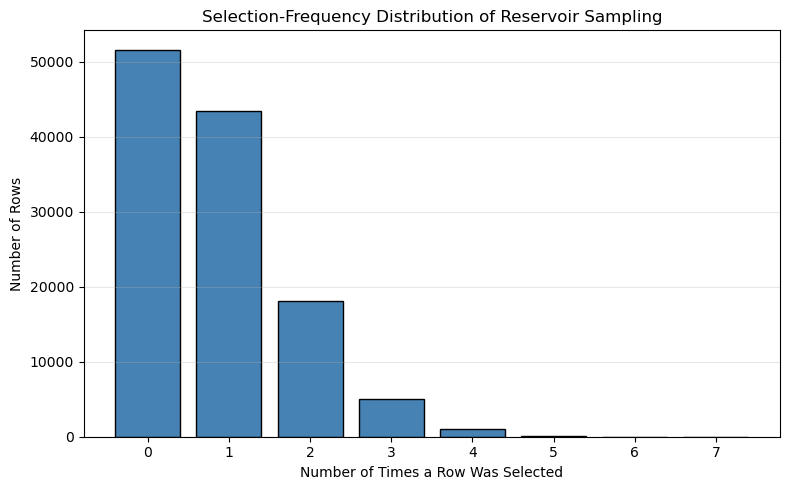

In [118]:
frequency_values, number_of_rows = np.unique(
    selection_counts,
    return_counts=True
)

plt.figure(figsize=(8, 5))

plt.bar(
    frequency_values,
    number_of_rows,
    color="steelblue",
    edgecolor="black"
)

plt.title(
    "Selection-Frequency Distribution of Reservoir Sampling"
)
plt.xlabel(
    "Number of Times a Row Was Selected"
)
plt.ylabel(
    "Number of Rows"
)
plt.xticks(frequency_values)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [119]:
position_results = pd.DataFrame({
    "row_position": np.arange(len(df)),
    "selection_count": selection_counts
})

position_results["position_group"] = pd.qcut(
    position_results["row_position"],
    q=10,
    labels=[
        "1", "2", "3", "4", "5",
        "6", "7", "8", "9", "10"
    ]
)

position_summary = (
    position_results
    .groupby(
        "position_group",
        observed=True
    )["selection_count"]
    .mean()
    .reset_index(name="mean_selection_frequency")
)

position_summary

,position_group,mean_selection_frequency
0,1,0.832231
1,2,0.827289
2,3,0.845213
3,4,0.830220
4,5,0.859452
5,6,0.833236
6,7,0.826535
7,8,0.842114
8,9,0.840690
9,10,0.838931


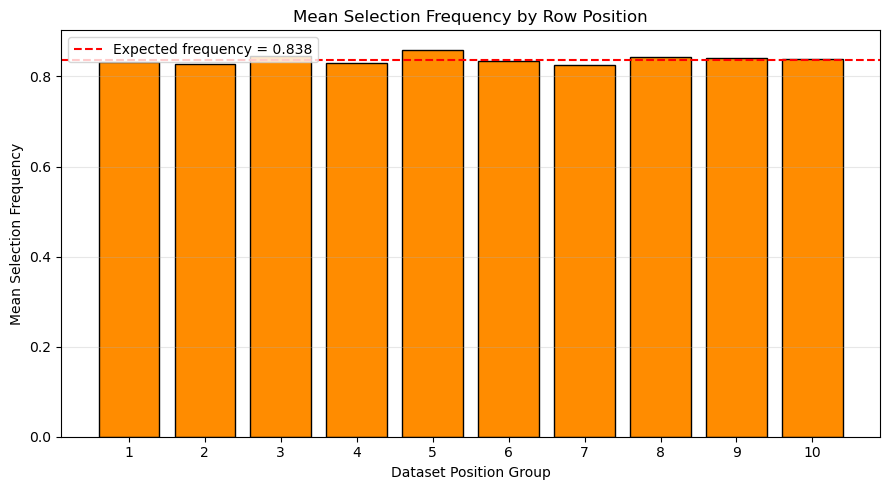

In [120]:
plt.figure(figsize=(9, 5))

plt.bar(
    position_summary["position_group"],
    position_summary["mean_selection_frequency"],
    color="darkorange",
    edgecolor="black"
)

plt.axhline(
    expected_frequency,
    color="red",
    linestyle="--",
    label=f"Expected frequency = {expected_frequency:.3f}"
)

plt.title("Mean Selection Frequency by Row Position")
plt.xlabel("Dataset Position Group")
plt.ylabel("Mean Selection Frequency")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

The reservoir sampling algorithm selected 500 rows from 119,390 rows in each of 200 runs, producing 100,000 selections in total.
The theoretical probability of selecting any row in one run was 0.004188, or approximately 0.419%. 

The expected and observed average selection frequencies over 200 runs were both 0.838. 
Individual rows were selected different numbers of times because of randomness, but the ten dataset-position groups had similar mean frequencies, ranging from approximately 0.827 to 0.859. Therefore, the results indicate that early and late rows had approximately equal probabilities of selection.

In [121]:
#PART 2.2
from sklearn.model_selection import train_test_split
from scipy.stats import entropy

In [122]:
sample_size = int(len(df) * 0.10)

print("Full dataset size:", len(df))
print("Sample size:", sample_size)

Full dataset size: 119390
Sample size: 11939


In [123]:
random_sample = df.sample(
    n=sample_size,
    random_state=42
)
len(random_sample)

11939

In [124]:
stratified_sample, remaining_data = train_test_split(
    df,
    train_size=sample_size,
    stratify=df["is_canceled"],
    random_state=42
)

In [125]:
convenience_sample = (
    df.sort_values(
        by="lead_time",
        ascending=False
    )
    .head(sample_size)
)

In [126]:
print("Random sample:", len(random_sample))
print("Stratified sample:", len(stratified_sample))
print("Convenience sample:", len(convenience_sample))

Random sample: 11939
Stratified sample: 11939
Convenience sample: 11939


In [127]:
def class_distribution(data):
    return (
        data["is_canceled"]
        .value_counts(normalize=True)
        .reindex([0, 1], fill_value=0)
    )

In [128]:
full_distribution = class_distribution(df)
random_distribution = class_distribution(random_sample)
stratified_distribution = class_distribution(stratified_sample)
convenience_distribution = class_distribution(convenience_sample)

In [129]:
distribution_table = pd.DataFrame({
    "Full dataset": full_distribution,
    "Simple random": random_distribution,
    "Stratified": stratified_distribution,
    "Convenience": convenience_distribution
}).T

distribution_table.columns = [
    "Not canceled (0)",
    "Canceled (1)"
]

distribution_table = (
    distribution_table * 100
).round(2)

distribution_table

,Not canceled (0),Canceled (1)
Full dataset,62.96,37.04
Simple random,62.22,37.78
Stratified,62.96,37.04
Convenience,33.01,66.99


In [130]:
def calculate_kl(sample_distribution, full_distribution):
    return entropy(
        sample_distribution.values,
        full_distribution.values
    )
    

In [131]:
random_kl = calculate_kl(
    random_distribution,
    full_distribution
)

stratified_kl = calculate_kl(
    stratified_distribution,
    full_distribution
)

convenience_kl = calculate_kl(
    convenience_distribution,
    full_distribution
)

In [132]:
comparison_table = pd.DataFrame({
    "sampling_method": [
        "Simple random",
        "Stratified",
        "Convenience"
    ],
    "sample_size": [
        len(random_sample),
        len(stratified_sample),
        len(convenience_sample)
    ],
    "not_canceled_percent": [
        random_distribution[0] * 100,
        stratified_distribution[0] * 100,
        convenience_distribution[0] * 100
    ],
    "canceled_percent": [
        random_distribution[1] * 100,
        stratified_distribution[1] * 100,
        convenience_distribution[1] * 100
    ],
    "kl_divergence": [
        random_kl,
        stratified_kl,
        convenience_kl
    ]
})

comparison_table.round({
    "not_canceled_percent": 2,
    "canceled_percent": 2,
    "kl_divergence": 6
})

,sampling_method,sample_size,not_canceled_percent,canceled_percent,kl_divergence
0,Simple random,11939,62.22,37.78,0.000118
1,Stratified,11939,62.96,37.04,0.000000
2,Convenience,11939,33.01,66.99,0.183790


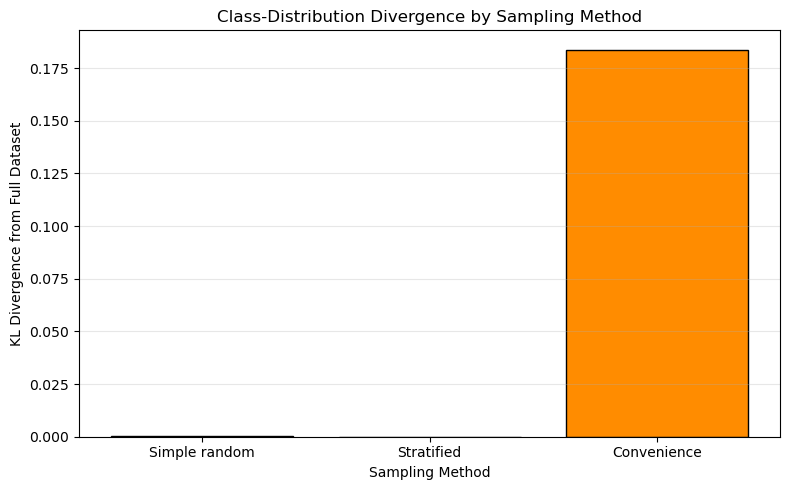

In [133]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_table["sampling_method"],
    comparison_table["kl_divergence"],
    color=["steelblue", "seagreen", "darkorange"],
    edgecolor="black"
)

plt.title("Class-Distribution Divergence by Sampling Method")
plt.xlabel("Sampling Method")
plt.ylabel("KL Divergence from Full Dataset")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

All three sampling methods used the same sample size of 11,939 rows. Stratified sampling preserved the original class distribution exactly and produced the lowest KL divergence of 0.000000. Simple random sampling was also representative, with a small KL divergence of 0.000118. Convenience sampling produced the largest divergence of 0.183790 because selecting bookings with the highest lead times increased the cancellation rate from 37.04% to 66.99%. This distorted class balance could cause a classifier to overpredict cancellations and perform poorly on normally distributed data.

In [134]:
#2.3
sampling_df = df[
    (df["adr"].notna()) &
    (df["adr"] >= 0)
].copy()

In [135]:
sample_sizes = [100, 250, 500, 1000, 2500, 5000]

In [136]:
full_data_mean = sampling_df["adr"].mean()
threshold = 0.05 * full_data_mean

print("Full-data mean ADR:", round(full_data_mean, 3))
print("Maximum acceptable CI width:", round(threshold, 3))

Full-data mean ADR: 101.832
Maximum acceptable CI width: 5.092


In [137]:
def bootstrap_mean_ci(
    values,
    n_bootstrap=1000,
    confidence_level=0.95,
    seed=42
):
    rng = np.random.default_rng(seed)
    bootstrap_means = []

    for _ in range(n_bootstrap):
        bootstrap_sample = rng.choice(
            values,
            size=len(values),
            replace=True
        )

        bootstrap_means.append(
            bootstrap_sample.mean()
        )

    alpha = 1 - confidence_level

    lower_bound = np.percentile(
        bootstrap_means,
        100 * alpha / 2
    )

    upper_bound = np.percentile(
        bootstrap_means,
        100 * (1 - alpha / 2)
    )

    return lower_bound, upper_bound

In [138]:
results = []

for n in sample_sizes:
    stratified_sample, _ = train_test_split(
        sampling_df,
        train_size=n,
        stratify=sampling_df["is_canceled"],
        random_state=42
    )

    sample_mean = stratified_sample["adr"].mean()

    ci_lower, ci_upper = bootstrap_mean_ci(
        stratified_sample["adr"].to_numpy(),
        n_bootstrap=1000,
        confidence_level=0.95,
        seed=42
    )

    ci_width = ci_upper - ci_lower

    results.append({
        "sample_size": n,
        "sample_mean": sample_mean,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "ci_width": ci_width,
        "width_percent_of_full_mean": (
            ci_width / full_data_mean * 100
        ),
        "below_5_percent": ci_width < threshold
    })

In [139]:
sample_size_results = pd.DataFrame(results)

sample_size_results.round({
    "sample_mean": 3,
    "ci_lower": 3,
    "ci_upper": 3,
    "ci_width": 3,
    "width_percent_of_full_mean": 2
})

,sample_size,sample_mean,ci_lower,ci_upper,ci_width,width_percent_of_full_mean,below_5_percent
0,100,105.944,96.643,116.993,20.350,19.98,False
1,250,107.142,100.929,113.249,12.320,12.10,False
2,500,105.117,100.901,109.741,8.840,8.68,False
3,1000,103.658,100.895,106.554,5.659,5.56,False
4,2500,102.612,100.788,104.535,3.746,3.68,True
5,5000,102.298,101.016,103.690,2.674,2.63,True


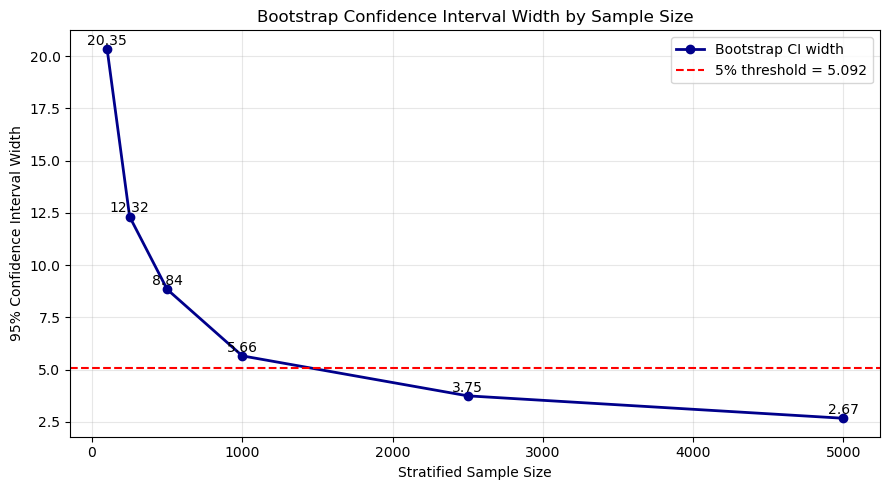

In [140]:
plt.figure(figsize=(9, 5))

plt.plot(
    sample_size_results["sample_size"],
    sample_size_results["ci_width"],
    marker="o",
    linewidth=2,
    color="darkblue",
    label="Bootstrap CI width"
)

plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label=f"5% threshold = {threshold:.3f}"
)

for x, y in zip(
    sample_size_results["sample_size"],
    sample_size_results["ci_width"]
):
    plt.text(
        x,
        y + 0.2,
        f"{y:.2f}",
        ha="center"
    )

plt.title("Bootstrap Confidence Interval Width by Sample Size")
plt.xlabel("Stratified Sample Size")
plt.ylabel("95% Confidence Interval Width")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The blue line s generally go down as the sample size increases.

The red line represents the maximum acceptable width.

The first blue point below the red line is the smallest adequate sample size.

In [141]:
adequate_samples = sample_size_results[
    sample_size_results["below_5_percent"]
]

if len(adequate_samples) > 0:
    smallest_adequate_n = adequate_samples[
        "sample_size"
    ].min()

    print(
        "Smallest adequate sample size:",
        smallest_adequate_n
    )
else:
    print(
        "None of the tested sample sizes "
        "produced a CI width below 5% "
        "of the full-data mean."
    )

Smallest adequate sample size: 2500


Using 1,000 bootstrap iterations, the 95% confidence interval became narrower as the stratified sample size increased.

The full-data mean ADR was 101.832, so the required maximum interval width was 5.092, which is 5% of the full-data mean. 

The first sample size below this threshold was 2,500, with a mean ADR of 102.612 and a confidence interval of [100.788, 104.535], giving a width of 3.746. Therefore, 2,500 is the smallest adequate sample size among the tested values.

In [142]:
#3.1
import statsmodels.api as sm

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

In [143]:
numeric_features = (
    df.select_dtypes(include=np.number)
      .drop(
          columns=[
              "is_canceled",
              "agent",
              "company"
          ],
          errors="ignore"
      )
      .copy()
)

In [144]:
print("Number of numeric features:", numeric_features.shape[1])

print("\nNumeric features:")
print(numeric_features.columns.tolist())

Number of numeric features: 18

Numeric features:
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_nights']


In [145]:
numeric_features.isna().sum()

lead_time                         0
arrival_date_year                 0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          4
babies                            0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
booking_changes                   0
days_in_waiting_list              0
adr                               0
required_car_parking_spaces       0
total_of_special_requests         0
total_nights                      0
dtype: int64

In [146]:
numeric_features = numeric_features.fillna(
    numeric_features.median()
)

In [147]:
def calculate_vif(X):
    X_with_constant = sm.add_constant(
        X,
        has_constant="add"
    )

    vif_values = []

    for i, feature in enumerate(X.columns, start=1):
        vif = variance_inflation_factor(
            X_with_constant.values,
            i
        )

        vif_values.append({
            "feature": feature,
            "vif": vif
        })

    return (
        pd.DataFrame(vif_values)
        .sort_values(
            by="vif",
            ascending=False
        )
        .reset_index(drop=True)
    )

In [148]:
def iterative_vif_removal(X, threshold=10):
    X_reduced = X.copy()
    removal_history = []

    while True:
        current_vif = calculate_vif(X_reduced)

        highest_vif = current_vif.loc[0, "vif"]
        highest_feature = current_vif.loc[0, "feature"]

        if highest_vif < threshold:
            break

        removal_history.append({
            "removed_feature": highest_feature,
            "vif_before_removal": highest_vif
        })

        X_reduced = X_reduced.drop(
            columns=highest_feature
        )

    removal_history = pd.DataFrame(removal_history)

    return X_reduced, current_vif, removal_history

In [149]:
# Initial VIF values
initial_vif = calculate_vif(numeric_features)

print("Initial VIF values:")
display(initial_vif.round(3))


C:\Users\aizat\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


Initial VIF values:


,feature,vif
0,total_nights,inf
1,stays_in_weekend_nights,inf
2,stays_in_week_nights,inf
3,arrival_date_year,1.649
4,arrival_date_week_number,1.580
5,adr,1.343
6,is_repeated_guest,1.264
7,previous_bookings_not_canceled,1.244
8,lead_time,1.187
9,children,1.128


In [150]:
# Iterative removal
X_vif_reduced, final_vif, removal_history = (
    iterative_vif_removal(
        numeric_features,
        threshold=10
    )
)


print(
    "Original number of features:",
    numeric_features.shape[1]
)

print(
    "Number of removed features:",
    len(removal_history)
)

print(
    "Final number of features:",
    X_vif_reduced.shape[1]
)

print("\nRemoved features:")
display(removal_history)

print("\nFinal VIF values:")
display(final_vif.round(3))

print(
    "\nMaximum final VIF:",
    round(final_vif["vif"].max(), 3)
)

C:\Users\aizat\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


Original number of features: 18
Number of removed features: 1
Final number of features: 17

Removed features:


,removed_feature,vif_before_removal
0,total_nights,inf



Final VIF values:


,feature,vif
0,arrival_date_year,1.649
1,arrival_date_week_number,1.580
2,stays_in_week_nights,1.379
3,stays_in_weekend_nights,1.346
4,adr,1.343
5,is_repeated_guest,1.264
6,previous_bookings_not_canceled,1.244
7,lead_time,1.187
8,children,1.128
9,adults,1.118



Maximum final VIF: 1.649


Initially, 18 numeric features were evaluated using VIF. The total_nights feature had an infinite VIF because it was an exact linear combination of stays_in_week_nights and stays_in_weekend_nights, so it was removed. After removal, all 17 remaining features had VIF values below 10, with a maximum VIF of 1.649 for arrival_date_year. Therefore, the final numeric feature set does not contain problematic multicollinearity.

In [151]:
#3.2
X = X_vif_reduced.copy()
y = df["is_canceled"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (119390, 17)
y shape: (119390,)


In [152]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(
    X,
    y,
    random_state=42
)

mi_results = pd.DataFrame({
    "feature": X.columns,
    "mi_score": mi_scores
}).sort_values(
    by="mi_score",
    ascending=False
)

mi_results

,feature,mi_score
0,lead_time,0.080078
14,adr,0.077507
10,previous_cancellations,0.040393
16,total_of_special_requests,0.039312
15,required_car_parking_spaces,0.029531
12,booking_changes,0.018965
13,days_in_waiting_list,0.016696
6,adults,0.013014
5,stays_in_week_nights,0.012072
11,previous_bookings_not_canceled,0.007766


In [153]:
filter_features = (
    mi_results
    .head(6)["feature"]
    .tolist()
)

print("Filter method top 6:")
print(filter_features)

Filter method top 6:
['lead_time', 'adr', 'previous_cancellations', 'total_of_special_requests', 'required_car_parking_spaces', 'booking_changes']


In [154]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

In [155]:
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

logistic_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rfecv = RFECV(
    estimator=logistic_model,
    step=1,
    cv=cv_strategy,
    scoring="f1",
    min_features_to_select=6,
    n_jobs=-1
)

rfecv.fit(X_scaled, y)

RFECV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
      estimator=LogisticRegression(class_weight='balanced', max_iter=2000,
                                   random_state=42),
      min_features_to_select=6, n_jobs=-1, scoring='f1')

In [156]:
rfecv_selected = X.columns[rfecv.support_].tolist()

print(
    "Number of features retained by RFECV:",
    rfecv.n_features_
)

print("RFECV retained features:")
print(rfecv_selected)

Number of features retained by RFECV: 16
RFECV retained features:
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


In [157]:
rfecv_coefficients = np.abs(
    rfecv.estimator_.coef_[0]
)

wrapper_ranking = pd.DataFrame({
    "feature": rfecv_selected,
    "coefficient_strength": rfecv_coefficients
}).sort_values(
    by="coefficient_strength",
    ascending=False
)

wrapper_features = (
    wrapper_ranking
    .head(6)["feature"]
    .tolist()
)

print("Wrapper method top 6:")
print(wrapper_features)

Wrapper method top 6:
['previous_cancellations', 'required_car_parking_spaces', 'previous_bookings_not_canceled', 'total_of_special_requests', 'lead_time', 'booking_changes']


In [158]:
from sklearn.ensemble import RandomForestClassifier

forest_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

forest_model.fit(X, y)

RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

In [159]:
embedded_results = pd.DataFrame({
    "feature": X.columns,
    "importance": forest_model.feature_importances_
}).sort_values(
    by="importance",
    ascending=False
)

embedded_results

,feature,importance
0,lead_time,0.244984
14,adr,0.174054
3,arrival_date_day_of_month,0.103896
2,arrival_date_week_number,0.102717
16,total_of_special_requests,0.083969
5,stays_in_week_nights,0.056209
10,previous_cancellations,0.042644
12,booking_changes,0.041634
15,required_car_parking_spaces,0.035563
4,stays_in_weekend_nights,0.032865


In [160]:
embedded_features = (
    embedded_results
    .head(6)["feature"]
    .tolist()
)

print("Embedded method top 6:")
print(embedded_features)

Embedded method top 6:
['lead_time', 'adr', 'arrival_date_day_of_month', 'arrival_date_week_number', 'total_of_special_requests', 'stays_in_week_nights']


In [161]:
selection_table = pd.DataFrame({
    "feature": X.columns
})

selection_table["Filter_MI"] = (
    selection_table["feature"]
    .isin(filter_features)
)

selection_table["Wrapper_RFECV"] = (
    selection_table["feature"]
    .isin(wrapper_features)
)

selection_table["Embedded_RF"] = (
    selection_table["feature"]
    .isin(embedded_features)
)

selection_table["number_of_methods"] = (
    selection_table[
        [
            "Filter_MI",
            "Wrapper_RFECV",
            "Embedded_RF"
        ]
    ]
    .sum(axis=1)
)

selection_table = selection_table.sort_values(
    by=["number_of_methods", "feature"],
    ascending=[False, True]
)

selection_table

,feature,Filter_MI,Wrapper_RFECV,Embedded_RF,number_of_methods
0,lead_time,True,True,True,3
16,total_of_special_requests,True,True,True,3
14,adr,True,False,True,2
12,booking_changes,True,True,False,2
10,previous_cancellations,True,True,False,2
15,required_car_parking_spaces,True,True,False,2
3,arrival_date_day_of_month,False,False,True,1
2,arrival_date_week_number,False,False,True,1
11,previous_bookings_not_canceled,False,True,False,1
5,stays_in_week_nights,False,False,True,1


In [162]:
selected_by_all = selection_table.loc[
    selection_table["number_of_methods"] == 3,
    "feature"
].tolist()

print("Selected by all three methods:")
print(selected_by_all)

Selected by all three methods:
['lead_time', 'total_of_special_requests']


In [163]:
selected_by_one = selection_table.loc[
    selection_table["number_of_methods"] == 1,
    "feature"
].tolist()

print("Selected by only one method:")
print(selected_by_one)

Selected by only one method:
['arrival_date_day_of_month', 'arrival_date_week_number', 'previous_bookings_not_canceled', 'stays_in_week_nights']


In [164]:
only_one_details = selection_table[
    selection_table["number_of_methods"] == 1
][[
    "feature",
    "Filter_MI",
    "Wrapper_RFECV",
    "Embedded_RF"
]]

only_one_details

,feature,Filter_MI,Wrapper_RFECV,Embedded_RF
3,arrival_date_day_of_month,False,False,True
2,arrival_date_week_number,False,False,True
11,previous_bookings_not_canceled,False,True,False
5,stays_in_week_nights,False,False,True


The three methods agreed on lead_time and total_of_special_requests, indicating that these features provide consistently useful information for predicting booking cancellation. 
Mutual Information and RFECV also selected booking_changes, previous_cancellations, and required_car_parking_spaces, 
while Mutual Information and Random Forest both selected adr. 

Four features were selected by only one method: arrival_date_day_of_month, arrival_date_week_number, and stays_in_week_nights by Random Forest, and previous_bookings_not_canceled by RFECV. 

This disagreement is expected because Mutual Information evaluates features individually, RFECV evaluates their contribution to Logistic Regression’s F1 score, and Random Forest captures nonlinear relationships and interactions.

In [165]:
#3.3
X_all = numeric_features.copy()

In [166]:
X_vif = X_vif_reduced.copy()

In [167]:
X_wrapper = X_vif_reduced[
    wrapper_features
].copy()

In [168]:
y = df["is_canceled"].copy()

In [169]:
print("All features:", X_all.shape)
print("VIF-reduced features:", X_vif.shape)
print("Wrapper-selected features:", X_wrapper.shape)

All features: (119390, 18)
VIF-reduced features: (119390, 17)
Wrapper-selected features: (119390, 6)


In [170]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [171]:
model_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )
])

In [172]:
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [173]:
def evaluate_feature_set(
    X,
    y,
    feature_set_name,
    model,
    cv
):
    scores = cross_validate(
        estimator=model,
        X=X,
        y=y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1": "f1"
        },
        return_train_score=False,
        n_jobs=1
    )

    return {
        "feature_set": feature_set_name,
        "number_of_features": X.shape[1],
        "mean_accuracy": scores[
            "test_accuracy"
        ].mean(),
        "std_accuracy": scores[
            "test_accuracy"
        ].std(),
        "mean_f1": scores[
            "test_f1"
        ].mean(),
        "std_f1": scores[
            "test_f1"
        ].std(),
        "mean_training_time": scores[
            "fit_time"
        ].mean(),
        "total_training_time": scores[
            "fit_time"
        ].sum()
    }

In [174]:
evaluation_results = []

evaluation_results.append(
    evaluate_feature_set(
        X=X_all,
        y=y,
        feature_set_name="All original features",
        model=model_pipeline,
        cv=cv_strategy
    )
)

evaluation_results.append(
    evaluate_feature_set(
        X=X_vif,
        y=y,
        feature_set_name="VIF-reduced features",
        model=model_pipeline,
        cv=cv_strategy
    )
)

evaluation_results.append(
    evaluate_feature_set(
        X=X_wrapper,
        y=y,
        feature_set_name="Wrapper-selected features",
        model=model_pipeline,
        cv=cv_strategy
    )
)

In [175]:
performance_table = pd.DataFrame(
    evaluation_results
)

performance_table.round({
    "mean_accuracy": 4,
    "std_accuracy": 4,
    "mean_f1": 4,
    "std_f1": 4,
    "mean_training_time": 4,
    "total_training_time": 4
})

,feature_set,number_of_features,mean_accuracy,std_accuracy,mean_f1,std_f1,mean_training_time,total_training_time
0,All original features,18,0.7179,0.0025,0.6582,0.0035,0.2266,1.1329
1,VIF-reduced features,17,0.7179,0.0026,0.6582,0.0035,0.2595,1.2976
2,Wrapper-selected features,6,0.7129,0.0013,0.6504,0.0025,0.1603,0.8015


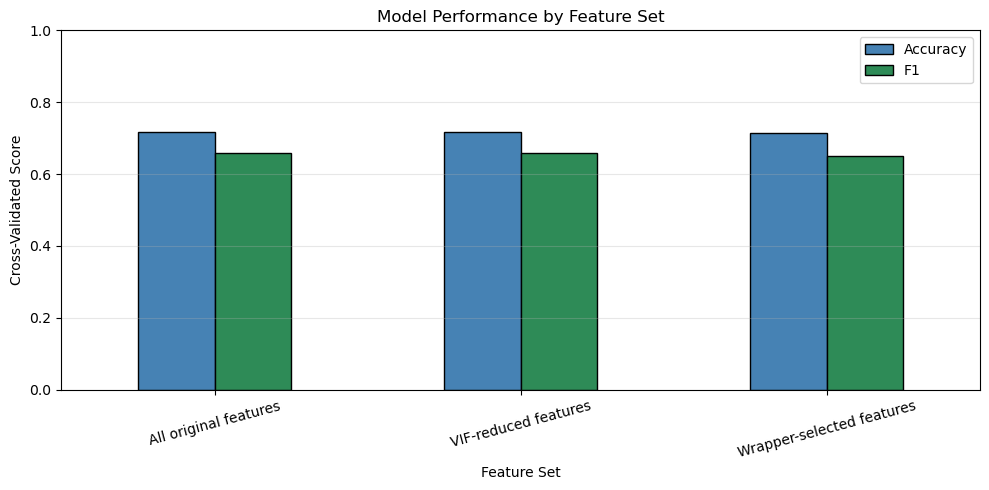

In [176]:
plot_data = performance_table.set_index(
    "feature_set"
)[[
    "mean_accuracy",
    "mean_f1"
]]

plot_data.plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "seagreen"],
    edgecolor="black"
)

plt.title("Model Performance by Feature Set")
plt.xlabel("Feature Set")
plt.ylabel("Cross-Validated Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(["Accuracy", "F1"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

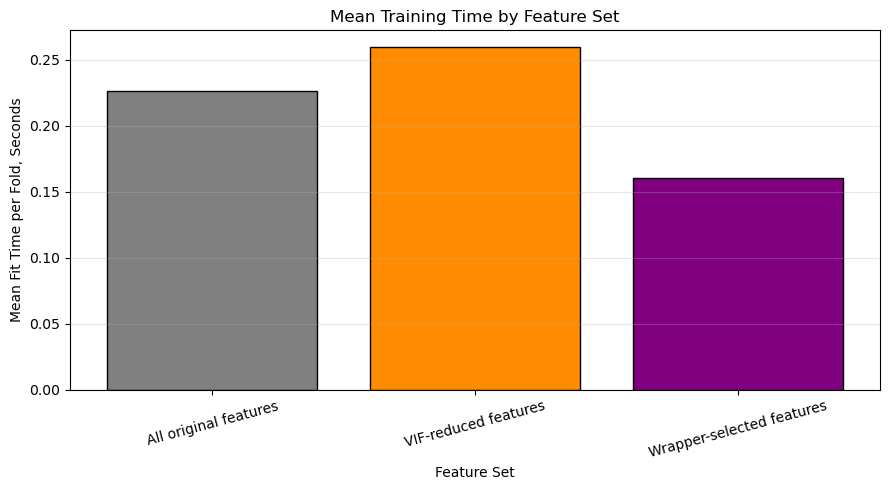

In [177]:
plt.figure(figsize=(9, 5))

plt.bar(
    performance_table["feature_set"],
    performance_table["mean_training_time"],
    color=["gray", "darkorange", "purple"],
    edgecolor="black"
)

plt.title("Mean Training Time by Feature Set")
plt.xlabel("Feature Set")
plt.ylabel("Mean Fit Time per Fold, Seconds")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

The original and VIF-reduced feature sets produced identical mean accuracy of 0.7179 and mean F1 of 0.6582, showing that removing the multicollinear total_nights feature did not reduce predictive performance. 

The wrapper-selected six-feature set trained approximately 37.1% faster than the original set, but its accuracy decreased to 0.7129 and its F1 score decreased to 0.6504. 

All three models had low variation across the five folds, indicating stable results. 

Therefore, the VIF-reduced set provides a best balance because it: 

preserved the highest accuracy: 71.79%;

preserved the highest F1: 0.6582;

removed perfect multicollinearity;

trained slightly faster than the original set.

In [178]:
#part 4.1
engineered_df = df.copy()
# Feature 1: total duration of the stay
engineered_df["total_nights"] = (
    engineered_df["stays_in_weekend_nights"] +
    engineered_df["stays_in_week_nights"]
)

In [179]:
# Feature 2: total number of guests
engineered_df["total_guests"] = (
    engineered_df["adults"] +
    engineered_df["children"].fillna(0) +
    engineered_df["babies"]
)

In [180]:
# Feature 3: approximate total booking value
engineered_df["estimated_booking_value"] = (
    engineered_df["adr"] *
    engineered_df["total_nights"]
)

In [181]:
previous_total = (
    engineered_df["previous_cancellations"] +
    engineered_df["previous_bookings_not_canceled"]
)

In [182]:
# Feature 4: proportion of previous bookings cancelled
engineered_df["previous_cancellation_rate"] = (
    engineered_df["previous_cancellations"] /
    previous_total.replace(0, np.nan)
).fillna(0)

In [183]:
# Display original and engineered features
engineered_df[[
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "total_nights",
    "adults",
    "children",
    "babies",
    "total_guests",
    "adr",
    "estimated_booking_value",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "previous_cancellation_rate"
]].head(10)

,stays_in_weekend_nights,stays_in_week_nights,total_nights,adults,children,babies,total_guests,adr,estimated_booking_value,previous_cancellations,previous_bookings_not_canceled,previous_cancellation_rate
0,0,0,0,2,0.0,0,2.0,0.0,0.0,0,0,0.0
1,0,0,0,2,0.0,0,2.0,0.0,0.0,0,0,0.0
2,0,1,1,1,0.0,0,1.0,75.0,75.0,0,0,0.0
3,0,1,1,1,0.0,0,1.0,75.0,75.0,0,0,0.0
4,0,2,2,2,0.0,0,2.0,98.0,196.0,0,0,0.0
5,0,2,2,2,0.0,0,2.0,98.0,196.0,0,0,0.0
6,0,2,2,2,0.0,0,2.0,107.0,214.0,0,0,0.0
7,0,2,2,2,0.0,0,2.0,103.0,206.0,0,0,0.0
8,0,3,3,2,0.0,0,2.0,82.0,246.0,0,0,0.0
9,0,3,3,2,0.0,0,2.0,105.5,316.5,0,0,0.0


In [184]:
new_features = [
    "total_nights",
    "total_guests",
    "estimated_booking_value",
    "previous_cancellation_rate"
]

engineered_df[new_features].describe().round(3)

,total_nights,total_guests,estimated_booking_value,previous_cancellation_rate
count,119390.000,119390.000,119390.000,119390.000
mean,3.428,1.968,357.848,0.050
std,2.557,0.722,335.910,0.217
min,0.000,0.000,-63.800,0.000
25%,2.000,2.000,146.000,0.000
50%,3.000,2.000,267.000,0.000
75%,4.000,2.000,446.250,0.000
max,69.000,55.000,7590.000,1.000


In [185]:
engineered_df[new_features].isna().sum()

total_nights                  0
total_guests                  0
estimated_booking_value       0
previous_cancellation_rate    0
dtype: int64

Four new features were created by combining related original attributes. total_nights represents the complete stay duration, while total_guests represents the complete booking-party size. estimated_booking_value combines the daily rate with stay duration to approximate the booking’s total financial value, and previous_cancellation_rate describes cancellation behaviour relative to the customer’s full booking history. These features contain information that the original attributes do not express individually.

In [186]:
#4.2
month_mapping = {
    "January": 1,
    "February": 2,
    "March": 3,
    "April": 4,
    "May": 5,
    "June": 6,
    "July": 7,
    "August": 8,
    "September": 9,
    "October": 10,
    "November": 11,
    "December": 12
}
engineered_df["arrival_month"] = (
    engineered_df["arrival_date_month"]
    .map(month_mapping)
)

In [187]:
engineered_df["arrival_date"] = pd.to_datetime(
    {
        "year": engineered_df["arrival_date_year"],
        "month": engineered_df["arrival_month"],
        "day": engineered_df[
            "arrival_date_day_of_month"
        ]
    },
    errors="coerce"
)

In [188]:
engineered_df["arrival_date"].isna().sum()

0

In [189]:
engineered_df["arrival_year"] = (
    engineered_df["arrival_date"].dt.year
)

In [190]:
engineered_df["arrival_month"] = (
    engineered_df["arrival_date"].dt.month
)

In [191]:
engineered_df["arrival_day_of_week"] = (
    engineered_df["arrival_date"].dt.dayofweek
)

In [192]:
engineered_df["is_weekend"] = (
    engineered_df["arrival_day_of_week"] >= 5
).astype(int)

In [193]:
# Cyclical encoding for month
engineered_df["month_sin"] = np.sin(
    2 * np.pi *
    (engineered_df["arrival_month"] - 1) / 12
)

engineered_df["month_cos"] = np.cos(
    2 * np.pi *
    (engineered_df["arrival_month"] - 1) / 12
)

In [194]:
# Cyclical encoding for day of week
engineered_df["day_of_week_sin"] = np.sin(
    2 * np.pi *
    engineered_df["arrival_day_of_week"] / 7
)

engineered_df["day_of_week_cos"] = np.cos(
    2 * np.pi *
    engineered_df["arrival_day_of_week"] / 7
)

In [195]:
# Display the created date features
date_features = [
    "arrival_date",
    "arrival_year",
    "arrival_month",
    "arrival_day_of_week",
    "is_weekend",
    "month_sin",
    "month_cos",
    "day_of_week_sin",
    "day_of_week_cos"
]

engineered_df[date_features].head(10).round(3)

,arrival_date,arrival_year,arrival_month,arrival_day_of_week,is_weekend,month_sin,month_cos,day_of_week_sin,day_of_week_cos
0,2015-07-01,2015,7,2,0,0.0,-1.0,0.975,-0.223
1,2015-07-01,2015,7,2,0,0.0,-1.0,0.975,-0.223
2,2015-07-01,2015,7,2,0,0.0,-1.0,0.975,-0.223
3,2015-07-01,2015,7,2,0,0.0,-1.0,0.975,-0.223
4,2015-07-01,2015,7,2,0,0.0,-1.0,0.975,-0.223
5,2015-07-01,2015,7,2,0,0.0,-1.0,0.975,-0.223
6,2015-07-01,2015,7,2,0,0.0,-1.0,0.975,-0.223
7,2015-07-01,2015,7,2,0,0.0,-1.0,0.975,-0.223
8,2015-07-01,2015,7,2,0,0.0,-1.0,0.975,-0.223
9,2015-07-01,2015,7,2,0,0.0,-1.0,0.975,-0.223


In [196]:
month_encoding_table = pd.DataFrame({
    "month": np.arange(1, 13)
})

month_encoding_table["month_sin"] = np.sin(
    2 * np.pi *
    (month_encoding_table["month"] - 1) / 12
)

month_encoding_table["month_cos"] = np.cos(
    2 * np.pi *
    (month_encoding_table["month"] - 1) / 12
)

month_encoding_table.round(3)

,month,month_sin,month_cos
0,1,0.000,1.000
1,2,0.500,0.866
2,3,0.866,0.500
3,4,1.000,0.000
4,5,0.866,-0.500
5,6,0.500,-0.866
6,7,0.000,-1.000
7,8,-0.500,-0.866
8,9,-0.866,-0.500
9,10,-1.000,-0.000


The arrival date was reconstructed and decomposed into year, month, day of week and weekend status. Month and day of week were encoded using sine and cosine transformations because they are periodic variables. This encoding places December close to January and Sunday close to Monday, which ordinary integer encoding does not represent correctly. The resulting features allow a model to learn seasonal and weekly booking patterns more naturally.

In [197]:
#4.3
X_numeric = (
    engineered_df
    .select_dtypes(include=np.number)
    .drop(
        columns=[
            "is_canceled",
            "agent",
            "company"
        ],
        errors="ignore"
    )
    .replace([np.inf, -np.inf], np.nan)
    .copy()
)

y = engineered_df["is_canceled"].copy()

print("Number of original numeric features:", X_numeric.shape[1])
print(X_numeric.columns.tolist())

Number of original numeric features: 29
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_nights', 'total_guests', 'estimated_booking_value', 'previous_cancellation_rate', 'arrival_month', 'arrival_year', 'arrival_day_of_week', 'is_weekend', 'month_sin', 'month_cos', 'day_of_week_sin', 'day_of_week_cos']


In [198]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_numeric,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [199]:
#fill missing values
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

In [200]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_imputed
)

X_test_scaled = scaler.transform(
    X_test_imputed
)

In [201]:
from sklearn.decomposition import PCA

pca_full = PCA()

pca_full.fit(X_train_scaled)

PCA()

In [202]:
explained_variance = (
    pca_full.explained_variance_ratio_
)

cumulative_variance = np.cumsum(
    explained_variance
)

In [203]:
n_components_90 = (
    np.argmax(cumulative_variance >= 0.90) + 1
)

print(
    "Minimum components for 90% variance:",
    n_components_90
)

print(
    "Retained cumulative variance:",
    round(
        cumulative_variance[
            n_components_90 - 1
        ],
        4
    )
)

Minimum components for 90% variance: 17
Retained cumulative variance: 0.917


In [204]:
variance_table = pd.DataFrame({
    "component": np.arange(
        1,
        len(explained_variance) + 1
    ),
    "explained_variance_ratio": explained_variance,
    "cumulative_variance": cumulative_variance
})

variance_table["explained_percent"] = (
    variance_table[
        "explained_variance_ratio"
    ] * 100
)

variance_table["cumulative_percent"] = (
    variance_table[
        "cumulative_variance"
    ] * 100
)

variance_table.round({
    "explained_variance_ratio": 4,
    "cumulative_variance": 4,
    "explained_percent": 2,
    "cumulative_percent": 2
})

,component,explained_variance_ratio,cumulative_variance,explained_percent,cumulative_percent
0,1,0.1329,0.1329,13.29,13.29
1,2,0.1294,0.2623,12.94,26.23
2,3,0.0919,0.3542,9.19,35.42
3,4,0.0764,0.4306,7.64,43.06
4,5,0.0574,0.4880,5.74,48.80
5,6,0.0518,0.5398,5.18,53.98
6,7,0.0472,0.5871,4.72,58.71
7,8,0.0416,0.6287,4.16,62.87
8,9,0.0366,0.6653,3.66,66.53
9,10,0.0364,0.7017,3.64,70.17


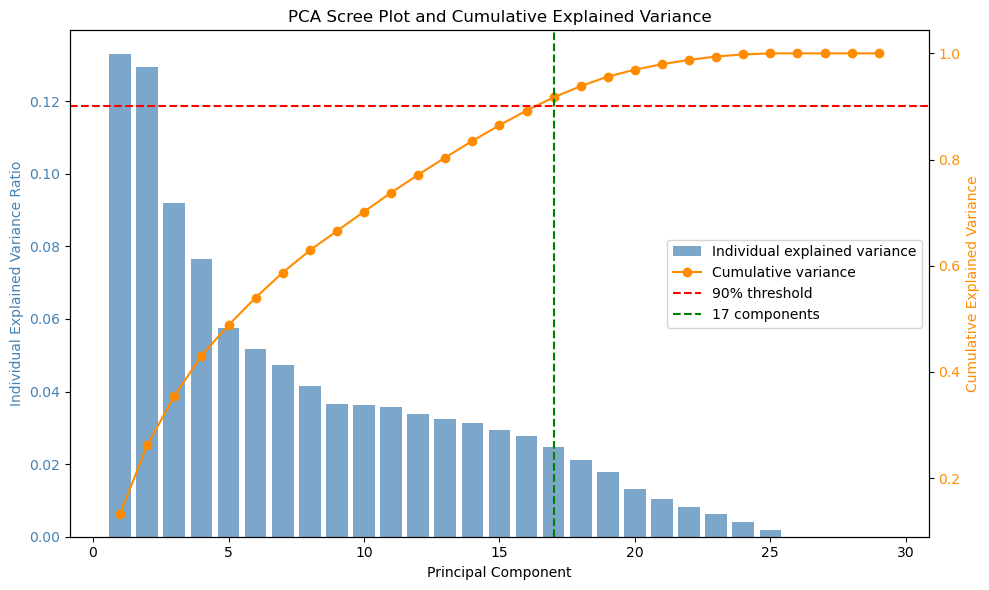

In [205]:
import matplotlib.pyplot as plt

components = np.arange(
    1,
    len(explained_variance) + 1
)

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.bar(
    components,
    explained_variance,
    color="steelblue",
    alpha=0.7,
    label="Individual explained variance"
)

ax1.set_xlabel("Principal Component")
ax1.set_ylabel(
    "Individual Explained Variance Ratio",
    color="steelblue"
)

ax1.tick_params(
    axis="y",
    labelcolor="steelblue"
)

ax2 = ax1.twinx()

ax2.plot(
    components,
    cumulative_variance,
    color="darkorange",
    marker="o",
    label="Cumulative variance"
)

ax2.axhline(
    0.90,
    color="red",
    linestyle="--",
    label="90% threshold"
)

ax2.axvline(
    n_components_90,
    color="green",
    linestyle="--",
    label=f"{n_components_90} components"
)

ax2.set_ylabel(
    "Cumulative Explained Variance",
    color="darkorange"
)

ax2.tick_params(
    axis="y",
    labelcolor="darkorange"
)

plt.title("PCA Scree Plot and Cumulative Explained Variance")

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()

ax2.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc="center right"
)

plt.tight_layout()
plt.show()

In [206]:
# PCA with minimum components for at least 90%
pca_90 = PCA(
    n_components=n_components_90
)

X_train_pca = pca_90.fit_transform(
    X_train_scaled
)

X_test_pca = pca_90.transform(
    X_test_scaled
)

print(
    "Original training shape:",
    X_train_scaled.shape
)

print(
    "PCA training shape:",
    X_train_pca.shape
)

Original training shape: (95512, 29)
PCA training shape: (95512, 17)


In [207]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score
)
import time

In [208]:
# Original-feature model
original_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

start_time = time.perf_counter()

original_model.fit(
    X_train_scaled,
    y_train
)

original_training_time = (
    time.perf_counter() - start_time
)

original_predictions = original_model.predict(
    X_test_scaled
)

original_accuracy = accuracy_score(
    y_test,
    original_predictions
)

original_f1 = f1_score(
    y_test,
    original_predictions
)

In [209]:
# PCA-feature model
pca_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

start_time = time.perf_counter()

pca_model.fit(
    X_train_pca,
    y_train
)

pca_training_time = (
    time.perf_counter() - start_time
)

pca_predictions = pca_model.predict(
    X_test_pca
)

pca_accuracy = accuracy_score(
    y_test,
    pca_predictions
)

pca_f1 = f1_score(
    y_test,
    pca_predictions
)

In [210]:
pca_comparison = pd.DataFrame({
    "representation": [
        "Original numeric features",
        "PCA components"
    ],
    "number_of_features": [
        X_train_scaled.shape[1],
        X_train_pca.shape[1]
    ],
    "retained_variance": [
        1.0,
        pca_90.explained_variance_ratio_.sum()
    ],
    "accuracy": [
        original_accuracy,
        pca_accuracy
    ],
    "f1_score": [
        original_f1,
        pca_f1
    ],
    "model_training_time": [
        original_training_time,
        pca_training_time
    ]
})

pca_comparison.round({
    "retained_variance": 4,
    "accuracy": 4,
    "f1_score": 4,
    "model_training_time": 4
})

,representation,number_of_features,retained_variance,accuracy,f1_score,model_training_time
0,Original numeric features,29,1.000,0.7208,0.6585,0.5874
1,PCA components,17,0.917,0.7158,0.6560,0.1816


PCA combined 29 original numeric features into new mathematical features called principal components. The first component preserved 13.29% of the original variation, and each additional component preserved more. The first 17 components together preserved 91.7%, making 17 the minimum number required to exceed the 90% threshold. This reduced the feature space from 29 original features to 17 components while discarding approximately 8.3% of the numeric variation

One disadvantage of using PCA-derived features is that they are difficult to interpret. The original engineered features, such as total_nights, total_guests, estimated_booking_value, and previous_cancellation_rate, have clear meanings for hotel bookings. In contrast, each PCA component combines many original features using mathematical weights, so we cannot easily explain what PC1 or PC2 represents. Therefore, even if a PCA component helps predict cancellation, it becomes harder for hotel managers to understand whether the prediction was influenced by stay duration, booking value, guest count, or previous cancellation behaviour.

In [211]:
#part 4
import time
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [212]:
class GroupAggregationTransformer(
    BaseEstimator,
    TransformerMixin
):
    def __init__(
        self,
        group_columns=None,
        value_column="adr"
    ):
        if group_columns is None:
            group_columns = [
                "hotel",
                "market_segment"
            ]

        self.group_columns = group_columns
        self.value_column = value_column

    def fit(self, X, y=None):
        X = X.copy()

        self.group_statistics_ = (
            X.groupby(self.group_columns)[
                self.value_column
            ]
            .agg(
                group_adr_mean="mean",
                group_adr_median="median",
                group_adr_std="std",
                group_booking_count="size"
            )
        )

        self.global_values_ = {
            "group_adr_mean": X[
                self.value_column
            ].mean(),

            "group_adr_median": X[
                self.value_column
            ].median(),

            "group_adr_std": X[
                self.value_column
            ].std(),

            "group_booking_count": 0
        }

        return self

    def transform(self, X):
        X = X.copy()

        group_index = pd.MultiIndex.from_frame(
            X[self.group_columns]
        )

        for column in self.group_statistics_.columns:
            values = (
                self.group_statistics_[column]
                .reindex(group_index)
                .to_numpy()
            )

            X[column] = values

            X[column] = X[column].fillna(
                self.global_values_[column]
            )

        return X

In [213]:
class HotelFeatureEngineer(
    BaseEstimator,
    TransformerMixin
):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        # Task 4.1: total stay duration
        X["total_nights"] = (
            X["stays_in_weekend_nights"] +
            X["stays_in_week_nights"]
        )

        # Task 4.1: total booking-party size
        X["total_guests"] = (
            X["adults"] +
            X["children"].fillna(0) +
            X["babies"]
        )

        # Task 4.1: approximate booking value
        X["estimated_booking_value"] = (
            X["adr"] *
            X["total_nights"]
        )

        # Task 4.1: previous cancellation rate
        previous_total = (
            X["previous_cancellations"] +
            X["previous_bookings_not_canceled"]
        )

        X["previous_cancellation_rate"] = (
            X["previous_cancellations"] /
            previous_total.replace(0, np.nan)
        ).fillna(0)

        # Task 4.2: month conversion
        month_mapping = {
            "January": 1,
            "February": 2,
            "March": 3,
            "April": 4,
            "May": 5,
            "June": 6,
            "July": 7,
            "August": 8,
            "September": 9,
            "October": 10,
            "November": 11,
            "December": 12
        }

        X["arrival_month"] = (
            X["arrival_date_month"]
            .map(month_mapping)
        )

        # Complete arrival date
        arrival_date = pd.to_datetime(
            {
                "year": X["arrival_date_year"],
                "month": X["arrival_month"],
                "day": X[
                    "arrival_date_day_of_month"
                ]
            },
            errors="coerce"
        )

        X["arrival_day_of_week"] = (
            arrival_date.dt.dayofweek
        )

        X["is_weekend"] = (
            X["arrival_day_of_week"] >= 5
        ).astype(int)

        # Cyclical month features
        X["month_sin"] = np.sin(
            2 * np.pi *
            (X["arrival_month"] - 1) / 12
        )

        X["month_cos"] = np.cos(
            2 * np.pi *
            (X["arrival_month"] - 1) / 12
        )

        # Cyclical weekday features
        X["day_of_week_sin"] = np.sin(
            2 * np.pi *
            X["arrival_day_of_week"] / 7
        )

        X["day_of_week_cos"] = np.cos(
            2 * np.pi *
            X["arrival_day_of_week"] / 7
        )

        return X

In [214]:
#The six wrapper-selected numeric features were:
selected_numeric_features = [
    "previous_cancellations",
    "required_car_parking_spaces",
    "previous_bookings_not_canceled",
    "total_of_special_requests",
    "lead_time",
    "booking_changes"
]

In [215]:
aggregation_features = [
    "group_adr_mean",
    "group_adr_median",
    "group_adr_std",
    "group_booking_count"
]

In [216]:
engineered_numeric_features = [
    "total_nights",
    "total_guests",
    "estimated_booking_value",
    "previous_cancellation_rate",
    "is_weekend",
    "month_sin",
    "month_cos",
    "day_of_week_sin",
    "day_of_week_cos"
]

In [217]:
numeric_columns = (
    selected_numeric_features +
    aggregation_features +
    engineered_numeric_features
)

In [218]:
categorical_columns = [
    "hotel",
    "market_segment",
    "deposit_type",
    "customer_type"
]

In [219]:
numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

In [220]:
#categorical preprocessing
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent"
        )
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

In [221]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_columns
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_columns
        )
    ],
    remainder="drop"
)

In [222]:
final_pipeline = Pipeline([
    (
        "aggregation",
        GroupAggregationTransformer()
    ),
    (
        "feature_engineering",
        HotelFeatureEngineer()
    ),
    (
        "preprocessing",
        preprocessor
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )
])

In [223]:
X_raw = df.drop(
    columns=["is_canceled"]
).copy()

y = df["is_canceled"].copy()

In [224]:
# we select a stratified 10% training sample:
X_train, X_test, y_train, y_test = (
    train_test_split(
        X_raw,
        y,
        train_size=0.10,
        stratify=y,
        random_state=42
    )
)

In [225]:
sampling_check = pd.DataFrame({
    "Full dataset": y.value_counts(
        normalize=True
    ),
    "Training sample": y_train.value_counts(
        normalize=True
    ),
    "Test data": y_test.value_counts(
        normalize=True
    )
}).T

sampling_check.columns = [
    "Not canceled",
    "Canceled"
]

sampling_check = (
    sampling_check * 100
).round(2)

sampling_check

,Not canceled,Canceled
Full dataset,62.96,37.04
Training sample,62.96,37.04
Test data,62.96,37.04


In [226]:
start_time = time.perf_counter()

final_pipeline.fit(
    X_train,
    y_train
)

training_time = (
    time.perf_counter() - start_time
)

In [227]:
start_time = time.perf_counter()

final_predictions = final_pipeline.predict(
    X_test
)

prediction_time = (
    time.perf_counter() - start_time
)

In [228]:
final_accuracy = accuracy_score(
    y_test,
    final_predictions
)

final_precision = precision_score(
    y_test,
    final_predictions
)

final_recall = recall_score(
    y_test,
    final_predictions
)

final_f1 = f1_score(
    y_test,
    final_predictions
)

In [229]:
final_results = pd.DataFrame({
    "metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 score",
        "Training time",
        "Prediction time"
    ],
    "value": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1,
        training_time,
        prediction_time
    ]
})

final_results.round(4)

,metric,value
0,Accuracy,0.7838
1,Precision,0.7029
2,Recall,0.7210
3,F1 score,0.7119
4,Training time,0.2545
5,Prediction time,0.4136


In [230]:
confusion = confusion_matrix(
    y_test,
    final_predictions
)

confusion_table = pd.DataFrame(
    confusion,
    index=[
        "Actual not canceled",
        "Actual canceled"
    ],
    columns=[
        "Predicted not canceled",
        "Predicted canceled"
    ]
)

confusion_table

,Predicted not canceled,Predicted canceled
Actual not canceled,55521,12128
Actual canceled,11103,28699


In [231]:
print(
    classification_report(
        y_test,
        final_predictions,
        target_names=[
            "Not canceled",
            "Canceled"
        ]
    )
)

              precision    recall  f1-score   support

Not canceled       0.83      0.82      0.83     67649
    Canceled       0.70      0.72      0.71     39802

    accuracy                           0.78    107451
   macro avg       0.77      0.77      0.77    107451
weighted avg       0.79      0.78      0.78    107451



The final workflow used a stratified 10% training sample because stratified sampling preserved the original cancellation distribution better than random and convenience sampling. 

The pipeline created ADR group statistics, engineered booking and cyclical date features, retained the selected feature subset, imputed missing values, scaled numeric variables and one-hot encoded categorical variables before training Logistic Regression.

On the remaining test data, the model achieved an accuracy of 0.7838, precision of 0.7029, recall of 0.7210 and F1 score of 0.7119. 

These results indicate that the pipeline correctly classified most bookings and detected approximately 72.1% of actual cancellations, although 11,103 cancelled bookings were still missed.